# 3 — Sessiz bölümleri çıkarma ve dizüstü–telefon spektrum karşılaştırması
Burada “çıkarma”, sessiz parçaları **ayrı dosyalara ayırmayı** ve konuşma kopyasından **kaldırmayı** kapsar.
Spektrum, sessiz parçalar birleştirilmeden ayrı hesaplanır ve Welch pencere sayısıyla ağırlıklı ortalanır.
Otomatik yöntem enerji eşiğidir; gerçek VAD değildir. Kısık konuşma sessiz sayılabilir, gürültülü sessizlik kaçabilir; aralıkları dinleyip doğrulayın.

## Kayıt protokolü
- Aynı odada aynı oturumda, mümkünse iki cihazda eşzamanlı kayıt alın.
- Yaklaşık 5 s sessizlik → 15–20 s aynı konuşma → 5 s sessizlik.
- Cihazları ağza benzer mesafede tutun; yön, uygulama, codec ve örnekleme hızını not edin.
- Mümkünse WAV/PCM kullanın; telefon yalnız M4A veriyorsa özgün M4A'yı saklayın.
- Telefon kaydını `data/raw/cihaz/cep_telefonu`, dizüstünü `data/raw/cihaz/dizustu` içine kopyalayın.
Telefonu bu notebook doğrudan kaydetmez; dosyasını aktarmanız gerekir. Dizüstü kaydı için isteğe bağlı hücre aşağıdadır.

In [1]:
from pathlib import Path
from datetime import datetime
import sys
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

PROJE = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
              if (p / 'src').is_dir() and (p / 'data/raw').is_dir()), None)
if PROJE is None:
    raise FileNotFoundError('VS Code ile ses-analizi proje klasörünü açın.')
if str(PROJE / 'src') not in sys.path:
    sys.path.insert(0, str(PROJE / 'src'))
from ses_arastirma import (audio_files, read_audio, save_csv, save_json, sha256,
                          ffmpeg_exe, ffmpeg_run, mdct, align_to_reference,
                          low_energy_intervals, interval_psd)
RUN = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
print('Python:', sys.executable)
print('Proje:', PROJE)

Python: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/.venv/bin/python
Proje: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi


## İsteğe bağlı: dizüstü kaydı
Varsayılan olarak kapalıdır. `KAYIT_AL = True` yapıp bu hücreyi çalıştırınca mikrofon 30 saniye kayıt alır. macOS VS Code mikrofon izni gerektirir.
Telefonu da aynı oturumda başlatın. Kaydı durdurmak için notebook hücresini kesebilirsiniz; tamamlanmamış kayıt kaydedilmez.

In [3]:
KAYIT_AL = False
if KAYIT_AL:
    import sounddevice as sd
    sr_kayit, saniye = 48000, 30
    sd.check_input_settings(samplerate=sr_kayit, channels=1)
    print('Kayıt: 5 s sessizlik, 20 s konuşma, 5 s sessizlik.')
    rec = sd.rec(sr_kayit*saniye, samplerate=sr_kayit, channels=1, dtype='float32')
    sd.wait()
    path = PROJE/'data/raw/cihaz/dizustu'/f'dizustu_{RUN}.wav'
    path.parent.mkdir(parents=True,exist_ok=True)
    sf.write(path,rec,sr_kayit,subtype='PCM_24')
    print('Kaydedildi:',path)
    print('Tepe genliği:',np.max(np.abs(rec)))
else:
    print('Kayıt kapalı; mevcut dosyaları kullanabilirsiniz.')

for cihaz in ['dizustu','cep_telefonu']:
    print('\n',cihaz)
    for p in audio_files(PROJE/'data/raw/cihaz'/cihaz):
        print(p.relative_to(PROJE))

Kayıt kapalı; mevcut dosyaları kullanabilirsiniz.

 dizustu
data/raw/cihaz/dizustu/macbook_ses.m4a

 cep_telefonu
data/raw/cihaz/cep_telefonu/iphone_ses.m4a


## Dosyalar ve eşikler
Yolları değiştirin. Kaynaklar tam okunur ve kendi örnekleme hızlarında analiz edilir; genlik normalizasyonu veya yeniden örnekleme yoktur.
`-45 dBFS` başlangıç eşiğidir, cihaz kazancına göre ayarlayın. Minimum sessizlik 0.3 s; konuşma sınırlarından 50 ms içeri girilir.
Bu notebook'ta RMS dBFS = 20 log10(RMS / 1). Bu değer kalibre edilmiş dB SPL değildir.

dizustu {'file': '/Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/raw/cihaz/dizustu/macbook_ses.m4a', 'native_sr': 48000, 'analysis_sr': 48000, 'channels': 1, 'selected_channel': 0, 'subtype': 'decoded float WAV', 'start_s': 0.0, 'duration_s': 21.610666666666667, 'peak': 0.2183990627527237}
Sessizlik adayları (s): [(0.05, 5.43), (9.11, 9.69), (10.29, 10.59), (12.47, 13.01), (13.73, 14.15), (14.75, 15.13), (15.67, 16.05), (16.43, 21.561)]


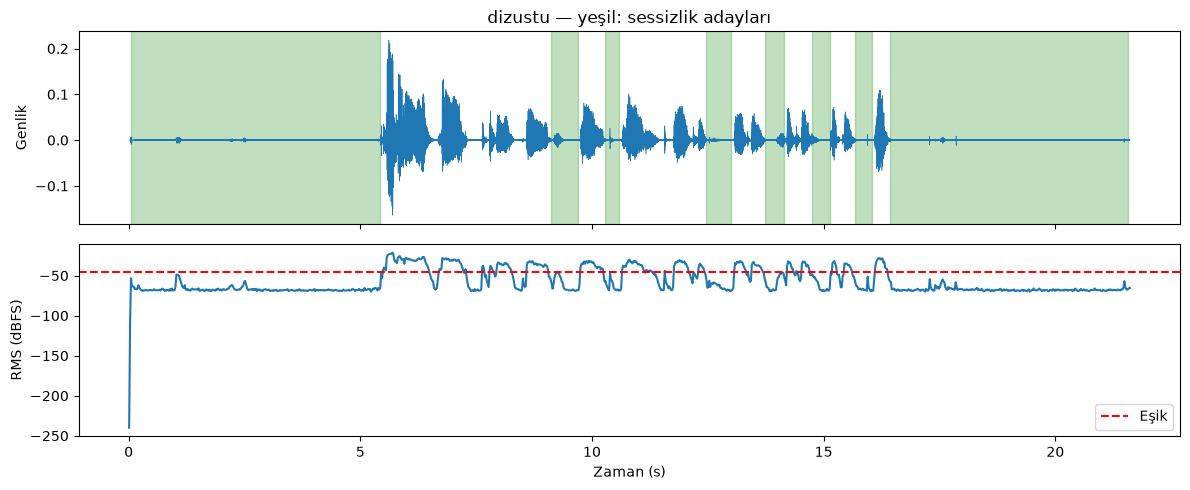

cep_telefonu {'file': '/Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/raw/cihaz/cep_telefonu/iphone_ses.m4a', 'native_sr': 48000, 'analysis_sr': 48000, 'channels': 1, 'selected_channel': 0, 'subtype': 'decoded float WAV', 'start_s': 0.0, 'duration_s': 21.524, 'peak': 0.09445349872112274}
Sessizlik adayları (s): [(0.05, 5.19), (7.01, 7.33), (8.85, 9.45), (10.03, 10.35), (11.03, 11.45), (12.23, 12.77), (13.49, 13.91), (14.49, 14.89), (15.39, 15.81), (16.17, 21.474)]


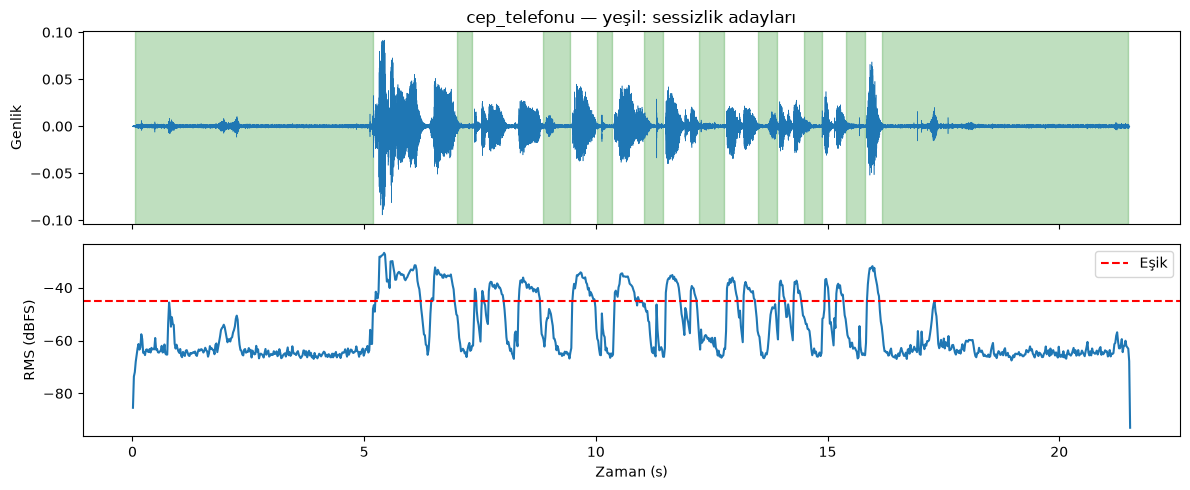

In [5]:
DOSYALAR = {
    'dizustu': PROJE/'data/raw/cihaz/dizustu/macbook_ses.m4a',
    'cep_telefonu': PROJE/'data/raw/cihaz/cep_telefonu/iphone_ses.m4a',
}
ESIK_DBFS = {'dizustu':-45.0, 'cep_telefonu':-45.0}
MIN_SESSIZ_S = .3
GUARD_S = .05
VERI, BILGI, ADAYLAR = {}, {}, {}
OUT = PROJE/'data/processed/cihaz'/RUN
FIG = PROJE/'outputs/figures/cihaz'/RUN
REPORT = PROJE/'outputs/reports/cihaz'/RUN
for p in [OUT,FIG,REPORT]: p.mkdir(parents=True,exist_ok=True)
for cihaz,path in DOSYALAR.items():
    y,sr,info = read_audio(path)
    VERI[cihaz] = (y,sr)
    BILGI[cihaz] = info
    intervals,t,levels = low_energy_intervals(y,sr,threshold_dbfs=ESIK_DBFS[cihaz],
        min_s=MIN_SESSIZ_S,guard_s=GUARD_S)
    ADAYLAR[cihaz] = intervals
    print(cihaz,info)
    print('Sessizlik adayları (s):',[(round(a/sr,3),round(b/sr,3)) for a,b in intervals])
    fig,axes = plt.subplots(2,1,figsize=(12,5),sharex=True)
    axes[0].plot(np.arange(len(y))/sr,y,linewidth=.4)
    for a,b in intervals: axes[0].axvspan(a/sr,b/sr,color='green',alpha=.25)
    axes[0].set(title=cihaz+' — yeşil: sessizlik adayları',ylabel='Genlik')
    axes[1].plot(t,levels)
    axes[1].axhline(ESIK_DBFS[cihaz],color='red',linestyle='--',label='Eşik')
    axes[1].set(xlabel='Zaman (s)',ylabel='RMS (dBFS)'); axes[1].legend()
    fig.tight_layout(); fig.savefig(FIG/f'{cihaz}_sessizlik_adaylari.png',dpi=160)
    plt.show()

## Sessiz aralıkları doğrula / elle seç
Otomatik adaylar yanlışsa eşikleri değiştirip üst hücreyi yeniden çalıştırın veya saniye cinsinden elle aralık girin.
Örneğin `ELLE_ARALIKLAR['dizustu'] = [(0.5, 4.5), (26, 29)]`.
Elle aralıklara ek sınır payı uygulanmaz; konuşma geçişlerinden uzak seçin. İlk üç parça dinleme için gösterilir; kısa kayıtlar önerilir.

In [6]:
ELLE_ARALIKLAR = {'dizustu':None, 'cep_telefonu':None}
ARALIKLAR = {}
for cihaz,(y,sr) in VERI.items():
    manual = ELLE_ARALIKLAR[cihaz]
    intervals = ADAYLAR[cihaz] if manual is None else [(round(a*sr),round(b*sr)) for a,b in manual]
    intervals = sorted(intervals)
    previous = 0
    for a,b in intervals:
        if not (0<=a<b<=len(y)) or a<previous:
            raise ValueError('Aralıklar kayıt içinde, sıralı ve örtüşmesiz olmalı.')
        previous = b
    if not intervals:
        raise ValueError(f'{cihaz}: sessiz bölüm yok; eşik veya elle aralıkları düzenleyin.')
    ARALIKLAR[cihaz] = intervals
    for i,(a,b) in enumerate(intervals[:3],1):
        print(cihaz,'sessiz bölüm',i,f'{a/sr:.2f}–{b/sr:.2f} s')
        display(Audio(y[a:b],rate=sr,normalize=False))

dizustu sessiz bölüm 1 0.05–5.43 s


dizustu sessiz bölüm 2 9.11–9.69 s


dizustu sessiz bölüm 3 10.29–10.59 s


cep_telefonu sessiz bölüm 1 0.05–5.19 s


cep_telefonu sessiz bölüm 2 7.01–7.33 s


cep_telefonu sessiz bölüm 3 8.85–9.45 s


## Sessiz parçaları ve sessizlikleri çıkarılmış konuşma kopyasını kaydet
Konuşma kopyası birleştirilirken yeni kesim sınırları oluşur; spektral ölçümler bu birleştirilmiş dosyadan alınmaz.
Özgün kayıt değiştirilmez. Zaman aralıkları CSV'de özgün kayıt zamanına göre saklanır.

In [7]:
rows = []
for cihaz,(y,sr) in VERI.items():
    folder = OUT/cihaz
    folder.mkdir(parents=True,exist_ok=True)
    keep = np.ones(len(y),dtype=bool)
    for i,(a,b) in enumerate(ARALIKLAR[cihaz],1):
        sf.write(folder/f'sessiz_{i:03}.wav',y[a:b],sr,subtype='FLOAT')
        keep[a:b] = False
        rows.append(dict(device=cihaz,source=str(DOSYALAR[cihaz]),segment=i,
            start_s=a/sr,end_s=b/sr,duration_s=(b-a)/sr,
            rms_dbfs=20*np.log10(max(np.sqrt(np.mean(y[a:b]**2)),1e-12))))
    if keep.any():
        sf.write(folder/'sessizlikleri_cikarilmis.wav',y[keep],sr,subtype='FLOAT')
save_csv(REPORT/'sessiz_araliklar.csv',rows)
save_json(REPORT/'ayarlar.json',dict(files=BILGI,thresholds=ESIK_DBFS,
    min_s=MIN_SESSIZ_S,guard_s=GUARD_S,manual=ELLE_ARALIKLAR,
    normalization=False,psd_window_s=.05,psd_overlap=.5,psd_detrend='constant',
    sha256={name:sha256(path) for name,path in DOSYALAR.items()}))
print('Ses parçaları:',OUT)

Ses parçaları: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/processed/cihaz/20261011_221838_494314


## Sessiz bölümlerin güç spektral yoğunluğu (PSD)
Her parçada 50 ms Hann pencereli Welch, %50 örtüşme ve DC giderme kullanılır; parçalar pencere sayısıyla ağırlıklı ortalanır.
Cihazların ortak geçerli frekans aralığı çizilir. İki grafik: dijital güç düzeyi ve toplam güce göre normalize şekil.
Farklar mikrofon, kazanç, ortam gürültüsü, otomatik kazanç, gürültü bastırma ve codec'in ortak etkisidir; yalnız mikrofon kalitesi yorumu yapılmaz.

dizustu Sessizlik toplam süresi (s): 13.110666666666667 PSD toplam gücü: 7.273852417956625e-07
cep_telefonu Sessizlik toplam süresi (s): 13.884 PSD toplam gücü: 1.2221404199585684e-06


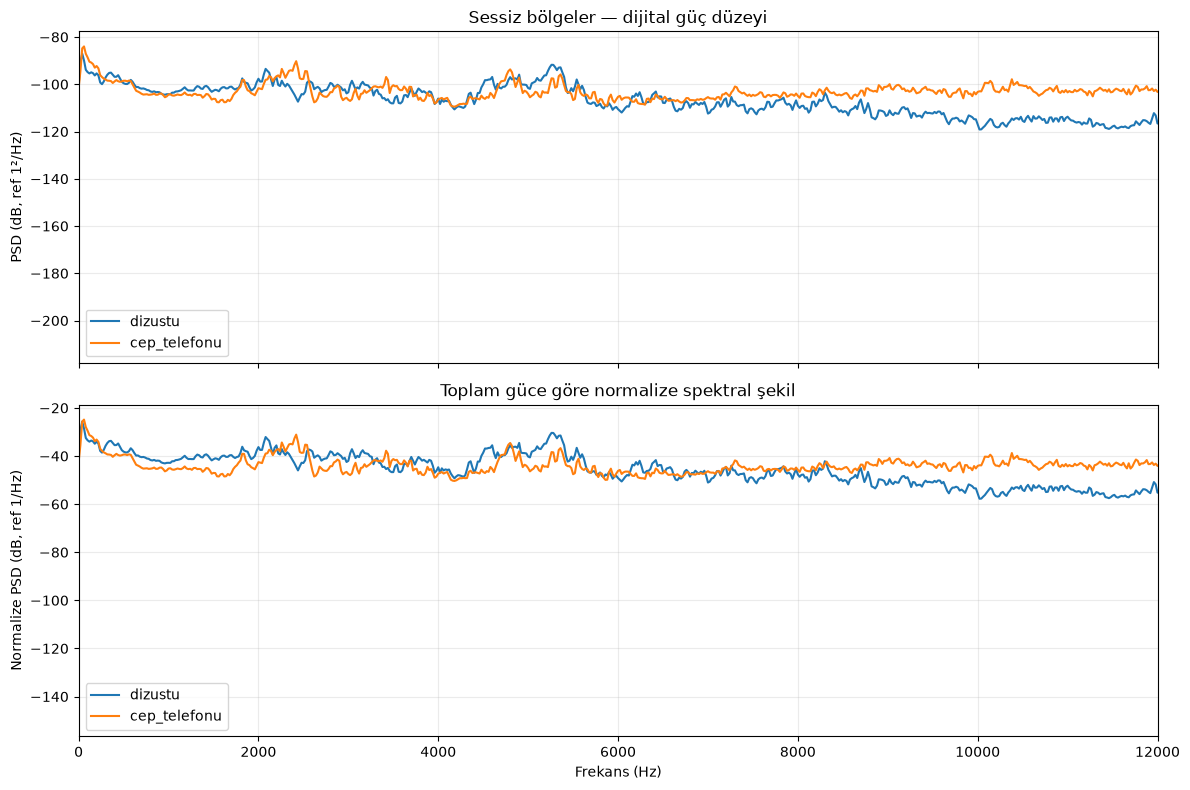

Grafikler: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/figures/cihaz/20261011_221838_494314
Raporlar: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/reports/cihaz/20261011_221838_494314


In [8]:
PSD = {}
fig,axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
for cihaz,(y,sr) in VERI.items():
    f,p = interval_psd(y,sr,ARALIKLAR[cihaz],window_s=.05)
    PSD[cihaz] = (f,p)
    power = np.trapezoid(p,f)
    axes[0].plot(f,10*np.log10(np.maximum(p,1e-24)),label=cihaz)
    shape = p/max(power,1e-24)
    axes[1].plot(f,10*np.log10(np.maximum(shape,1e-24)),label=cihaz)
    save_csv(REPORT/f'{cihaz}_sessizlik_psd.csv',
             [dict(frequency_hz=float(freq),psd=float(value)) for freq,value in zip(f,p)])
    print(cihaz, 'Sessizlik toplam süresi (s):',sum(b-a for a,b in ARALIKLAR[cihaz])/sr,
          'PSD toplam gücü:', power)
fmax = min(12000,*[sr/2 for _,sr in VERI.values()])
axes[0].set(title='Sessiz bölgeler — dijital güç düzeyi',ylabel='PSD (dB, ref 1²/Hz)')
axes[1].set(title='Toplam güce göre normalize spektral şekil',ylabel='Normalize PSD (dB, ref 1/Hz)',xlabel='Frekans (Hz)')
for ax in axes:
    ax.set_xlim(0,fmax); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(FIG/'sessizlik_psd_karsilastirma.png',dpi=160)
plt.show()
print('Grafikler:',FIG)
print('Raporlar:',REPORT)

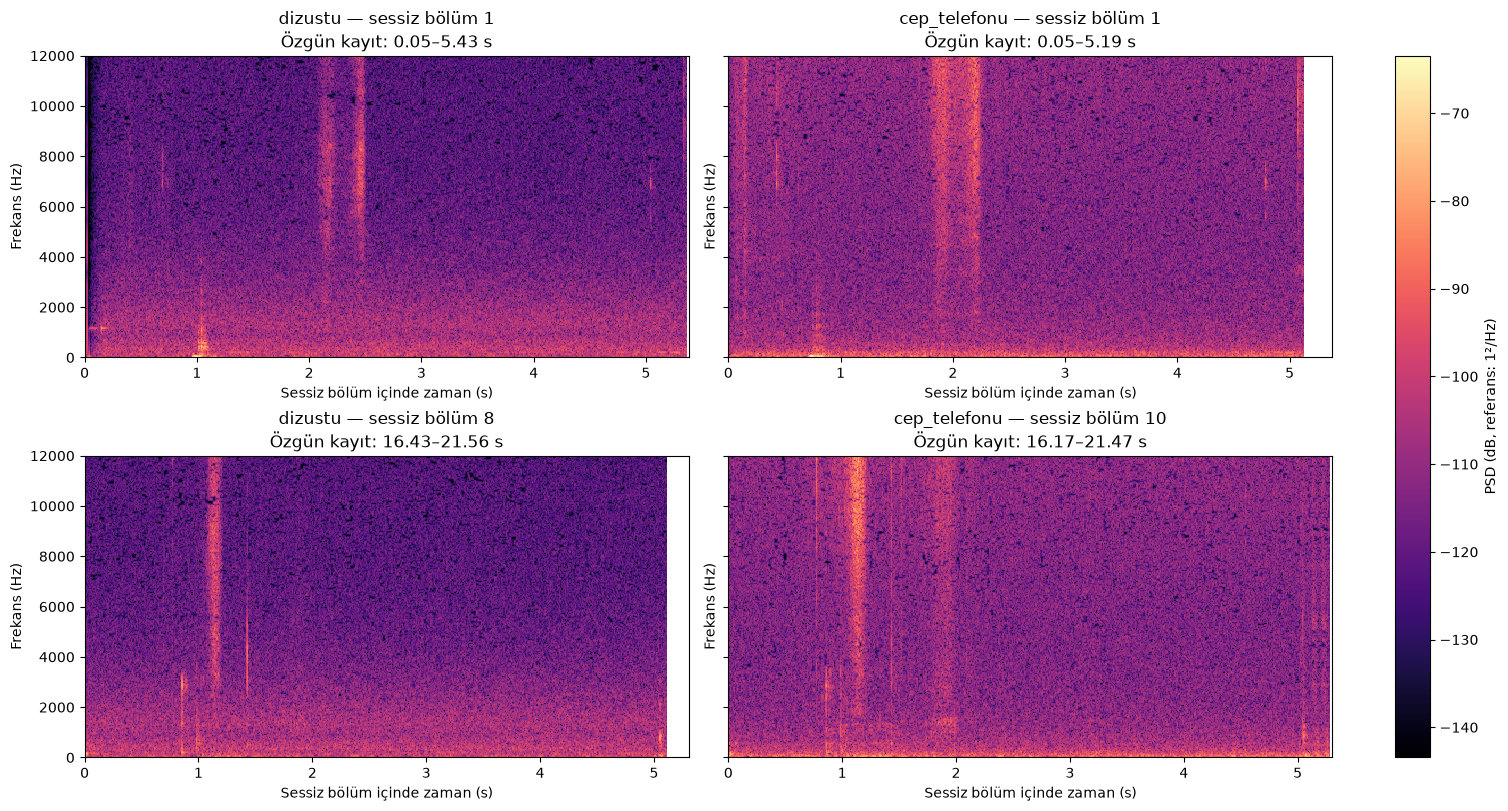

Kaydedildi: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/figures/cihaz/20261011_221838_494314/sessiz_spektrogramlar_yan_yana.png


In [10]:
from scipy import signal

# (Dizüstü sessiz bölüm numarası, telefon sessiz bölüm numarası)
ESLESMELER = [
    (1, 1),
    (8, 10),
]

FMAX = min(
    12000,
    VERI["dizustu"][1] / 2,
    VERI["cep_telefonu"][1] / 2,
)

PANELLER = []

for dizustu_no, telefon_no in ESLESMELER:
    satir = []

    for cihaz, bolum_no in [
        ("dizustu", dizustu_no),
        ("cep_telefonu", telefon_no),
    ]:
        y, sr = VERI[cihaz]
        araliklar = ARALIKLAR[cihaz]

        if not 1 <= bolum_no <= len(araliklar):
            raise ValueError(
                f"{cihaz}: {bolum_no}. bölüm yok. "
                f"Toplam {len(araliklar)} bölüm var."
            )

        a, b = araliklar[bolum_no - 1]
        parca = y[a:b]

        pencere = round(0.025 * sr)  # 25 ms
        adim = round(0.010 * sr)    # 10 ms

        if len(parca) < pencere:
            raise ValueError(
                f"{cihaz}, bölüm {bolum_no}: parça çok kısa."
            )

        f, t, guc = signal.spectrogram(
            parca,
            fs=sr,
            window="hann",
            nperseg=pencere,
            noverlap=pencere - adim,
            detrend="constant",
            scaling="density",
            mode="psd",
        )

        satir.append({
            "cihaz": cihaz,
            "bolum": bolum_no,
            "baslangic": a / sr,
            "bitis": b / sr,
            "sure": (b - a) / sr,
            "f": f,
            "t": t,
            "db": 10 * np.log10(np.maximum(guc, 1e-24)),
        })

    PANELLER.append(satir)

if not PANELLER:
    raise ValueError("En az bir bölüm eşleşmesi seç.")

# Tüm panellerde aynı renk ölçeği
VMAX = max(
    p["db"][p["f"] <= FMAX].max()
    for satir in PANELLER
    for p in satir
)
VMIN = VMAX - 80

fig, axes = plt.subplots(
    len(PANELLER),
    2,
    figsize=(15, 4 * len(PANELLER)),
    squeeze=False,
    sharey=True,
    layout="constrained",
)

for satir_no, satir in enumerate(PANELLER):
    # Her eşleşmede aynı zaman ölçeği; kısa parçanın sonu boş kalır.
    ortak_sure = max(p["sure"] for p in satir)

    for sutun_no, p in enumerate(satir):
        ax = axes[satir_no, sutun_no]

        im = ax.pcolormesh(
            p["t"],
            p["f"],
            p["db"],
            shading="auto",
            cmap="magma",
            vmin=VMIN,
            vmax=VMAX,
        )

        ax.set(
            title=(
                f'{p["cihaz"]} — sessiz bölüm {p["bolum"]}\n'
                f'Özgün kayıt: {p["baslangic"]:.2f}–'
                f'{p["bitis"]:.2f} s'
            ),
            xlabel="Sessiz bölüm içinde zaman (s)",
            ylabel="Frekans (Hz)",
            xlim=(0, ortak_sure),
            ylim=(0, FMAX),
        )

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="PSD (dB, referans: 1²/Hz)",
)

FIG.mkdir(parents=True, exist_ok=True)
dosya = FIG / "sessiz_spektrogramlar_yan_yana.png"
fig.savefig(dosya, dpi=160)
plt.show()

print("Kaydedildi:", dosya)

## Değerlendirme
Şebeke uğultusu ve harmonikleri, geniş bant dip gürültüsü, yüksek frekans kesilmesi ve bastırılan bantları inceleyin.
Normalize grafik gürültü düzeyini kaldırır; yalnız spektral şekli gösterir. Mutlak grafikte farklı cihaz kazançları doğrudan eşdeğer değildir.
Gerçek/sahte kayıtların sessiz bölümlerini incelemek için dosya yollarını değiştirip aynı akışı kullanabilirsiniz.

Kaynak: [SciPy Welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html).